In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.evaluation.metrics import confusion

sns.set_theme(style="whitegrid")
T = PROJECT_ROOT / "reports" / "tables"; FIG = PROJECT_ROOT / "reports" / "figures"
cv = pd.read_csv(T / "baselines_cv.csv")
show = ["model", "weighting", "features", "macro_f1_nsv", "f1nsv_fold_mean", "f1nsv_fold_std",
        "recall_N", "recall_S", "recall_V", "recall_F", "precision_S", "precision_V", "accuracy"]
print(cv[(cv.cv == "group") & (cv.features == "all")][show].round(3).to_string(index=False))

 model weighting features  macro_f1_nsv  f1nsv_fold_mean  f1nsv_fold_std  recall_N  recall_S  recall_V  recall_F  precision_S  precision_V  accuracy
logreg      none      all         0.597            0.593           0.039     0.967     0.068     0.748     0.014        0.118        0.728     0.926
logreg  balanced      all         0.520            0.529           0.053     0.737     0.234     0.766     0.159        0.037        0.572     0.726
    rf      none      all         0.620            0.630           0.079     0.946     0.104     0.847     0.000        0.213        0.693     0.916
    rf  balanced      all         0.628            0.644           0.099     0.959     0.122     0.909     0.005        0.208        0.657     0.932


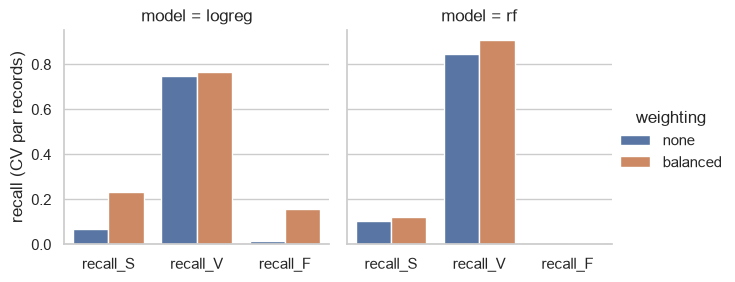

In [2]:
d = cv[(cv.cv == "group") & (cv.features == "all")]
rec = d.melt(id_vars=["model", "weighting"], value_vars=["recall_S", "recall_V", "recall_F"])
g = sns.catplot(data=rec, x="variable", y="value", hue="weighting", col="model", kind="bar", height=3.2)
g.set_axis_labels("", "recall (CV par records)"); plt.savefig(FIG / "baselines_weighting.png", dpi=150)

In [3]:
a = cv[(cv.cv == "group") & (cv.weighting == "balanced")]
print(a.pivot(index="model", columns="features", values="macro_f1_nsv").round(3))
print(a.pivot(index="model", columns="features", values="recall_S").round(3))
print("Écart-type entre plis (macro_f1_nsv, features=all) :",
      a[a.features == "all"].set_index("model")["f1nsv_fold_std"].round(3).to_dict())

features    all
model          
logreg    0.520
rf        0.628
features    all
model          
logreg    0.234
rf        0.122
Écart-type entre plis (macro_f1_nsv, features=all) : {'logreg': 0.053, 'rf': 0.099}


In [4]:
print(cv[cv.model == "rf"].query("weighting == 'balanced' and features == 'all'")
      [["cv", "macro_f1_nsv", "recall_S", "recall_V", "recall_F", "precision_S"]].round(3))

       cv  macro_f1_nsv  recall_S  recall_V  recall_F  precision_S
3   group         0.628     0.122     0.909     0.005        0.208
4  random         0.964     0.922     0.987     0.903        0.929


Meilleur modèle selon macro_f1_nsv : rf


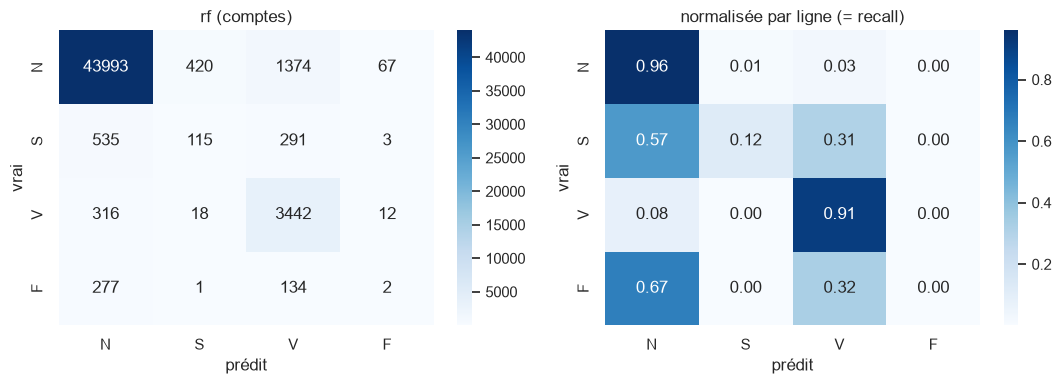

In [5]:
oof = np.load(T / "baselines_oof.npz")
best = cv[(cv.cv == "group") & (cv.weighting == "balanced") & (cv.features == "all")] \
    .sort_values("macro_f1_nsv", ascending=False).iloc[0]
key = f"{best.model}__balanced__all__group"
cm = confusion(oof["y"], oof[key])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", xticklabels="NSVF", yticklabels="NSVF", cmap="Blues", ax=ax[0])
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", xticklabels="NSVF",
            yticklabels="NSVF", cmap="Blues", ax=ax[1])
ax[0].set_title(f"{best.model} (comptes)"); ax[1].set_title("normalisée par ligne (= recall)")
for a_ in ax: a_.set_xlabel("prédit"); a_.set_ylabel("vrai")
plt.tight_layout(); plt.savefig(FIG / "baselines_confusion_cv.png", dpi=150)
print("Meilleur modèle selon macro_f1_nsv :", best.model)

In [6]:
import yaml
from src.models.baselines import feature_sets, fit_pipeline, make_pipeline
cfg = yaml.safe_load((PROJECT_ROOT / "configs" / "baselines.yaml").read_text(encoding="utf-8"))
df = pd.read_csv(PROJECT_ROOT / cfg["features"], dtype={"record_id": str})
df = df[df.split.isin(["train", "val"])]
cols = [c for c in df.columns if c not in ["record_id", "sample", "symbol", "label", "split"]]
pipe = make_pipeline("rf", cfg["models"]["rf"], True, cfg["seed"])
fit_pipeline(pipe, "rf", df[cols].to_numpy(np.float32), df["label"].to_numpy(), True)
imp = pd.Series(pipe.named_steps["clf"].feature_importances_, index=cols).sort_values(ascending=False)
print(imp.head(12).round(3))

rr_prev                0.104
rr_ratio_prev_local    0.083
rr_ratio_next_prev     0.073
s_kurtosis             0.068
rr_next                0.054
rr_local               0.046
s_skew                 0.035
f_rbp_0p5_5            0.035
f_centroid             0.034
f_rbp_2540             0.034
m_qrs_neg              0.031
f_rbp_1015             0.030
dtype: float64
